# Bagging Exercises

![Bagging.png](Assets/Bagging.png)

# Цели обучения

- Установить связь между понятиями «бутстреппинга» и «агрегирования» (более известного как «баггинг») для снижения дисперсии
- Применять алгоритм «Случайного леса», который позволяет ещё больше снизить корреляцию, наблюдаемую в моделях, построенных методом баггинга


## Введение

Для выполнения заданий на этой неделе мы будем использовать данные об оттоке клиентов из телекоммуникационной отрасли, которые мы рассматривали на первой неделе. Файл данных называется `Orange_Telecom_Churn_Data.csv`.

In [19]:
from __future__ import print_function
import os
data_path = [ 'data']

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix



## Вопрос 1

* Импортируйте данные об оттоке клиентов, содержащиеся в файле `Orange_Telecom_Churn_Data.csv`.
* Удалите все столбцы, которые, вероятно, не будут использоваться для прогнозирования.
* Осуществите соответствующее кодирование типов данных.

В прогнозе ни в коем случае не должно фигурировать номер телефона. И вряд ли потребуются код города или штат, если только нет оснований полагать, что модель учитывает какой-то очень конкретный географический фактор.

Проанализируйте типы данных. Всё выглядит нормально, за исключением того, что `int_plan` и `voice_mail_plan` необходимо кодировать как булевы значения.

In [22]:
filepath = os.sep.join(data_path + ['Orange_Telecom_Churn_Data.csv'])
churn_df = pd.read_csv(filepath)
churn_df.dtypes


state                             object
account_length                     int64
area_code                          int64
phone_number                      object
intl_plan                         object
voice_mail_plan                   object
number_vmail_messages              int64
total_day_minutes                float64
total_day_calls                    int64
total_day_charge                 float64
total_eve_minutes                float64
total_eve_calls                    int64
total_eve_charge                 float64
total_night_minutes              float64
total_night_calls                  int64
total_night_charge               float64
total_intl_minutes               float64
total_intl_calls                   int64
total_intl_charge                float64
number_customer_service_calls      int64
churned                             bool
dtype: object

In [23]:
churn_df = churn_df.drop(['state', 'area_code', 'phone_number'], axis=1)
churn_df.head()


,account_length,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,128,no,yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,107,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,137,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,84,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,75,yes,no,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [24]:
churn_df['intl_plan'] = churn_df['intl_plan'].map({'yes': 1, 'no': 0})
churn_df['voice_mail_plan'] = churn_df['voice_mail_plan'].map({'yes': 1, 'no': 0})
churn_df['churned'] = churn_df['churned'].astype(int)
churn_df.dtypes


account_length                     int64
intl_plan                          int64
voice_mail_plan                    int64
number_vmail_messages              int64
total_day_minutes                float64
total_day_calls                    int64
total_day_charge                 float64
total_eve_minutes                float64
total_eve_calls                    int64
total_eve_charge                 float64
total_night_minutes              float64
total_night_calls                  int64
total_night_charge               float64
total_intl_minutes               float64
total_intl_calls                   int64
total_intl_charge                float64
number_customer_service_calls      int64
churned                            int64
dtype: object

## Вопрос 2

* Проанализируйте распределение прогнозируемой переменной (`churned`).
* Разделите данные на обучающую и тестовую выборки. На основании распределения решите, следует ли использовать стратифицированное деление.
* Проанализируйте распределение предикторной переменной в обучающих и тестовых данных.

Учитывая асимметрию переменной-предиктора, давайте разбиваем данные, стратифицировав значения *churned*.

In [25]:
churn_df['churned'].value_counts(normalize=True)


churned
0    0.8586
1    0.1414
Name: proportion, dtype: float64

In [26]:
feature_cols = [c for c in churn_df.columns if c != 'churned']
X = churn_df[feature_cols]
y = churn_df['churned']

splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, test_idx = next(splitter.split(X, y))

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

print(X_train.shape, X_test.shape)


(3500, 17) (1500, 17)


In [27]:
print('train:')
print(y_train.value_counts(normalize=True))
print('test:')
print(y_test.value_counts(normalize=True))


train:
churned
0    0.858571
1    0.141429
Name: proportion, dtype: float64
test:
churned
0    0.858667
1    0.141333
Name: proportion, dtype: float64


## Вопрос 3

* Постройте модели «случайного леса» с различным количеством деревьев и оцените ошибку «out-of-bag» для каждой из этих моделей.
* Постройте график полученных ошибок «out-of-bag» в зависимости от количества деревьев.

*Подсказка:* поскольку изменяется только количество деревьев, можно использовать флаг `warm_start`, чтобы модель каждый раз просто добавляла новые деревья к существующей модели. Для обновления количества деревьев используйте метод `set_params`.

In [28]:
# Suppress warnings about too few trees from the early models

import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)


In [29]:
rf = RandomForestClassifier(oob_score=True, random_state=42, warm_start=True, n_jobs=-1)

tree_counts = [15, 20, 30, 40, 50, 100, 150, 200, 300, 400]
rows = []
for n in tree_counts:
    rf.set_params(n_estimators=n)
    rf.fit(X_train, y_train)
    rows.append({'n_trees': n, 'oob': 1 - rf.oob_score_})

rf_oob_df = pd.DataFrame(rows).set_index('n_trees')
rf_oob_df


,oob
n_trees,
15,0.059714
20,0.053429
30,0.049714
40,0.047429
50,0.049143
100,0.045143
150,0.045143
200,0.044857
300,0.044286


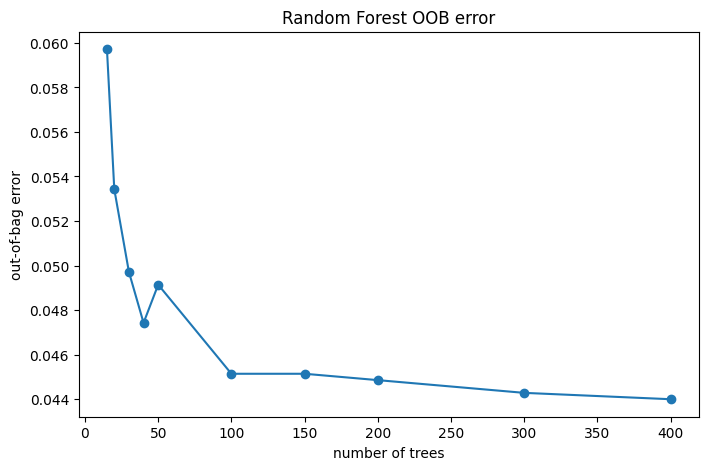

In [30]:
rf_oob_df.plot(legend=False, marker='o', figsize=(8, 5))
plt.xlabel('number of trees')
plt.ylabel('out-of-bag error')
plt.title('Random Forest OOB error')
plt.show()


Похоже, что количество ошибок стабилизировалось на уровне 100–150 деревьев.

## Вопрос 4

* Повторите задание из вопроса 3, используя дополнительные рандомизированные деревья (`ExtraTreesClassifier`). Обратите внимание, что для этой модели параметр `bootstrap` необходимо установить в значение `True`.
* Сравните ошибки метода «out-of-bag» для двух различных типов моделей.

In [31]:
et = ExtraTreesClassifier(oob_score=True, random_state=42, warm_start=True, bootstrap=True, n_jobs=-1)

rows = []
for n in tree_counts:
    et.set_params(n_estimators=n)
    et.fit(X_train, y_train)
    rows.append({'n_trees': n, 'oob': 1 - et.oob_score_})

et_oob_df = pd.DataFrame(rows).set_index('n_trees')
et_oob_df


,oob
n_trees,
15,0.080857
20,0.072000
30,0.069429
40,0.064286
50,0.067429
100,0.062857
150,0.061143
200,0.062571
300,0.060286


Объедините два датафрейма в один, чтобы упростить построение графиков.

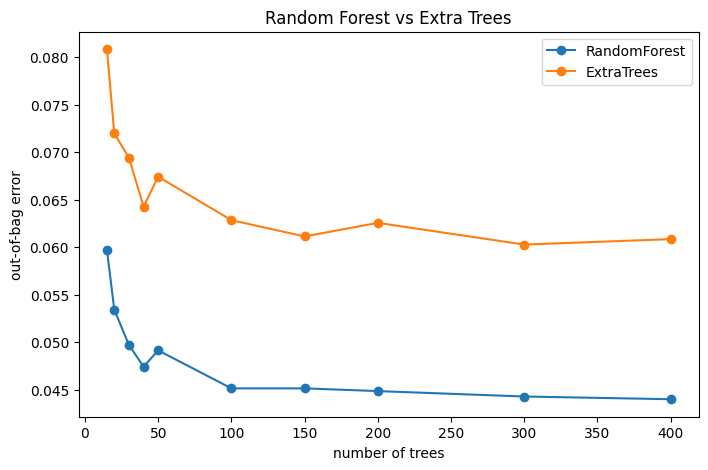

In [32]:
oob_df = pd.concat([
    rf_oob_df.rename(columns={'oob': 'RandomForest'}),
    et_oob_df.rename(columns={'oob': 'ExtraTrees'})
], axis=1)

oob_df.plot(marker='o', figsize=(8, 5))
plt.xlabel('number of trees')
plt.ylabel('out-of-bag error')
plt.title('Random Forest vs Extra Trees')
plt.show()


Модель «случайного леса» демонстрирует стабильно более высокую эффективность по сравнению с моделью «дополнительных рандомизированных деревьев».

## Вопрос 5

* Выберите одну из моделей, демонстрирующих хорошие результаты, и рассчитайте показатели ошибок и матрицу путаницы на тестовом наборе данных.
* Учитывая распределение предсказанных классов, какой показатель является наиболее важным? А какой может вводить в заблуждение?

In [33]:
rf_final = RandomForestClassifier(n_estimators=200, oob_score=True, random_state=42, n_jobs=-1)
rf_final.fit(X_train, y_train)

y_pred = rf_final.predict(X_test)

print('accuracy: ', accuracy_score(y_test, y_pred))
print('precision:', precision_score(y_test, y_pred))
print('recall:   ', recall_score(y_test, y_pred))
print('f1:       ', f1_score(y_test, y_pred))


accuracy:  0.9606666666666667
precision: 0.9526627218934911
recall:    0.7594339622641509
f1:        0.8451443569553806


In [34]:
confusion_matrix(y_test, y_pred)


array([[1280,    8],
       [  51,  161]])

Неудивительно, что показатель воспроизведения для класса «Ушедшие клиенты» (True) довольно низкий, поскольку их количество весьма невелико. Тем не менее, мы показываем лучшие результаты, чем при случайном угадывании: точность составляет 0,932 (против 0,85 при случайном угадывании).

## Вопрос 6

* Распечатайте или отобразите матрицу путаницы.
* Постройте кривые ROC-AUC и точность-воспроизводимость.
* Постройте график важности признаков.

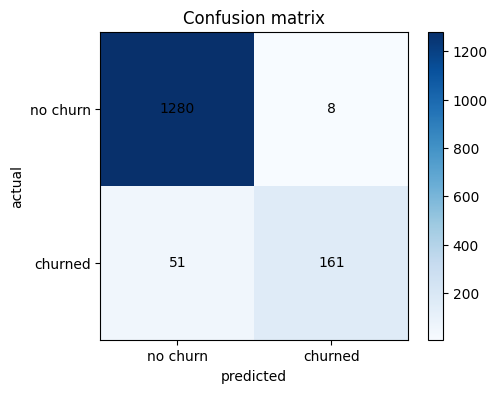

In [35]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xticks([0, 1], ['no churn', 'churned'])
plt.yticks([0, 1], ['no churn', 'churned'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')
plt.xlabel('predicted')
plt.ylabel('actual')
plt.title('Confusion matrix')
plt.show()


Кривые ROC-AUC и «точность-охватываемость».

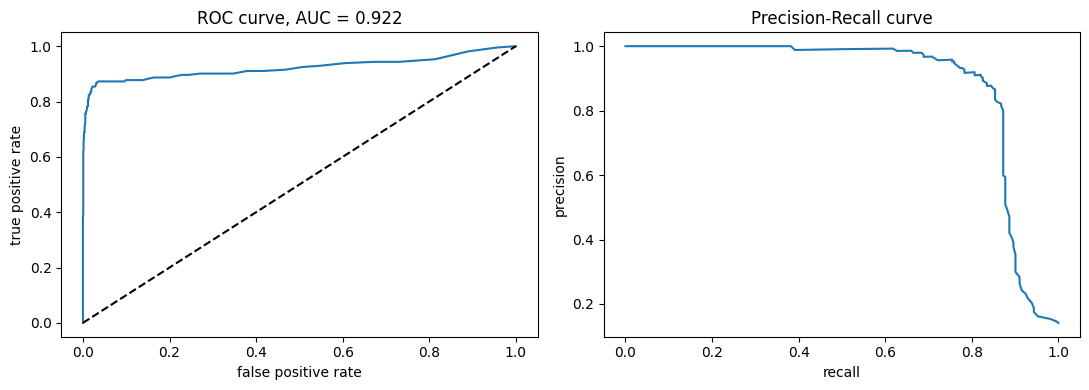

In [36]:
y_prob = rf_final.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_prob)
precision, recall, _ = precision_recall_curve(y_test, y_prob)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(fpr, tpr)
ax[0].plot([0, 1], [0, 1], 'k--')
ax[0].set_xlabel('false positive rate')
ax[0].set_ylabel('true positive rate')
ax[0].set_title('ROC curve, AUC = %.3f' % roc_auc_score(y_test, y_prob))

ax[1].plot(recall, precision)
ax[1].set_xlabel('recall')
ax[1].set_ylabel('precision')
ax[1].set_title('Precision-Recall curve')

plt.tight_layout()
plt.show()


Важность признаков. Общая ежедневная стоимость является наиболее значимым предиктором оттока клиентов.

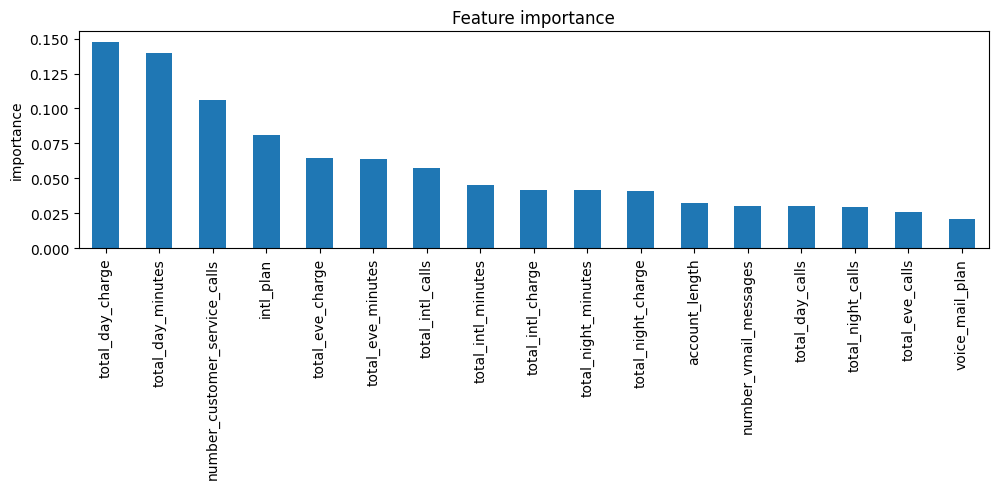

In [37]:
feat_imp = pd.Series(rf_final.feature_importances_, index=feature_cols).sort_values(ascending=False)

feat_imp.plot(kind='bar', figsize=(10, 5))
plt.ylabel('importance')
plt.title('Feature importance')
plt.tight_layout()
plt.show()
